# Project 4 — Dataset Audit and Preprocessing Evidence

**NYC Airbnb Open Data (2019)** | Run all cells top to bottom in VS Code.

Put `AB_NYC_2019.csv` in `week04/data/` and open this notebook from the `week04` project folder. This notebook performs **diagnostic analysis only**; all fitted preprocessing for model training is implemented in `pipeline.py`.

The code recreates the analyses discussed previously. **Outputs are recalculated from your own local CSV** rather than embedded or invented.

## 1. Load data and inspect its structure

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

path = Path("data/AB_NYC_2019.csv")
if not path.exists():
    raise FileNotFoundError(f"Place AB_NYC_2019.csv at {path.resolve()}")

df = pd.read_csv(path)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())
df.info()

Rows: 48895
Columns: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

## 2. Missingness and R1 dataset requirements

In [3]:
missing_table = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)
display(missing_table.round(2))

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include=["object", "string", "category"]).columns
category_counts = df[categorical_cols].nunique()
checks = {
    ">= 1000 rows and >= 8 columns": df.shape[0] >= 1000 and df.shape[1] >= 8,
    "Numeric variable with >=3% missing": (df[numeric_cols].isna().mean() >= 0.03).any(),
    "Categorical variable with <10 values": (category_counts < 10).any(),
    "Categorical variable with >30 values": (category_counts > 30).any()
}
for label, ok in checks.items():
    print(label, bool(ok))
print("\nCategorical unique values:")
print(category_counts.sort_values())

,missing_values,missing_percent
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03
id,0,0.00
host_id,0,0.00
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00


>= 1000 rows and >= 8 columns True
Numeric variable with >=3% missing True
Categorical variable with <10 values True
Categorical variable with >30 values True

Categorical unique values:
room_type                  3
neighbourhood_group        5
neighbourhood            221
last_review             1764
host_name              11452
name                   47905
dtype: int64


## 3. Numerical summary, skewness and histograms

,count,mean,std,min,25%,50%,75%,max,skew
id,48895.0,1.901714e+07,1.098311e+07,2539.000,9471945.000,1.967728e+07,2.915218e+07,3.648724e+07,-0.090
host_id,48895.0,6.762001e+07,7.861097e+07,2438.000,7822033.000,3.079382e+07,1.074344e+08,2.743213e+08,1.206
latitude,48895.0,4.072900e+01,5.500000e-02,40.500,40.690,4.072300e+01,4.076300e+01,4.091300e+01,0.237
longitude,48895.0,-7.395200e+01,4.600000e-02,-74.244,-73.983,-7.395600e+01,-7.393600e+01,-7.371300e+01,1.284
price,48895.0,1.527210e+02,2.401540e+02,0.000,69.000,1.060000e+02,1.750000e+02,1.000000e+04,19.119
minimum_nights,48895.0,7.030000e+00,2.051100e+01,1.000,1.000,3.000000e+00,5.000000e+00,1.250000e+03,21.827
number_of_reviews,48895.0,2.327400e+01,4.455100e+01,0.000,1.000,5.000000e+00,2.400000e+01,6.290000e+02,3.691
reviews_per_month,38843.0,1.373000e+00,1.680000e+00,0.010,0.190,7.200000e-01,2.020000e+00,5.850000e+01,3.130
calculated_host_listings_count,48895.0,7.144000e+00,3.295300e+01,1.000,1.000,1.000000e+00,2.000000e+00,3.270000e+02,7.933
availability_365,48895.0,1.127810e+02,1.316220e+02,0.000,0.000,4.500000e+01,2.270000e+02,3.650000e+02,0.763


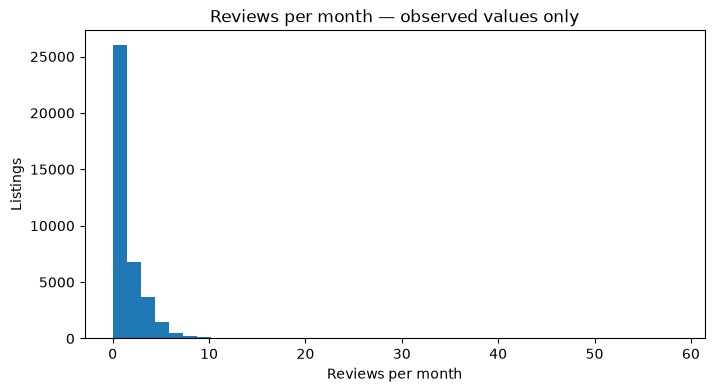

In [4]:
numeric_summary = df[numeric_cols].describe().T
numeric_summary["skew"] = df[numeric_cols].skew()
display(numeric_summary.round(3))

plt.figure(figsize=(8, 4))
plt.hist(df["reviews_per_month"].dropna(), bins=40)
plt.title("Reviews per month — observed values only")
plt.xlabel("Reviews per month")
plt.ylabel("Listings")
plt.show()

## 4. Complete column audit (R2)

In [5]:
audit_rows = []
for col in df.columns:
    data = df[col]
    if pd.api.types.is_numeric_dtype(data):
        summary = f"{data.min()} to {data.max()}"
        q1, q3 = data.quantile(0.25), data.quantile(0.75)
        iqr = q3 - q1
        outliers = int(((data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)).sum())
    else:
        summary = str(data.value_counts().head(3).index.tolist())
        outliers = "N/A"
    audit_rows.append({
        "column": col, "dtype": str(data.dtype),
        "% missing": round(data.isna().mean() * 100, 2),
        "distinct": int(data.nunique()),
        "min / max or top 3": summary,
        "outliers (IQR)": outliers,
        "proposed treatment": "To decide"
    })
audit = pd.DataFrame(audit_rows)
display(audit)

,column,dtype,% missing,distinct,min / max or top 3,outliers (IQR),proposed treatment
0,id,int64,0.00,48895,2539 to 36487245,0,To decide
1,name,str,0.03,47905,"['Hillside Hotel', 'Home away from home', 'New...",N/A,To decide
2,host_id,int64,0.00,37457,2438 to 274321313,1526,To decide
3,host_name,str,0.04,11452,"['Michael', 'David', 'Sonder (NYC)']",N/A,To decide
4,neighbourhood_group,str,0.00,5,"['Manhattan', 'Brooklyn', 'Queens']",N/A,To decide
5,neighbourhood,str,0.00,221,"['Williamsburg', 'Bedford-Stuyvesant', 'Harlem']",N/A,To decide
6,latitude,float64,0.00,19048,40.49979 to 40.91306,425,To decide
7,longitude,float64,0.00,14718,-74.24442 to -73.71299,2833,To decide
8,room_type,str,0.00,3,"['Entire home/apt', 'Private room', 'Shared ro...",N/A,To decide
9,price,int64,0.00,674,0 to 10000,2972,To decide


## 5. Investigate missing-review mechanism (R3)

In [6]:
missing_reviews = df["reviews_per_month"].isna()
review_comparison = pd.crosstab(
    df["number_of_reviews"] == 0,
    missing_reviews,
    rownames=["Zero reviews"],
    colnames=["Reviews/month missing"]
)
display(review_comparison)
missing_rate = df.groupby(df["number_of_reviews"] == 0)["reviews_per_month"].apply(lambda x: x.isna().mean() * 100)
print("Missing percentage by zero-review status:")
print(missing_rate.round(2))
print("Identical last_review and reviews_per_month missingness:",
      (df["last_review"].isna() == df["reviews_per_month"].isna()).all())

Reviews/month missing,False,True
Zero reviews,,
False,38843,0
True,0,10052


Missing percentage by zero-review status:
number_of_reviews
False      0.0
True     100.0
Name: reviews_per_month, dtype: float64
Identical last_review and reviews_per_month missingness: True


**Interpretation:** If missing review frequency aligns exactly with zero reviews, it is structurally explained by the observed review count. This provides evidence against MCAR, but observed data cannot conclusively distinguish MAR from MNAR.

## 6. Compare missing vs observed name/host-name rows

In [7]:
for col in ["name", "host_name"]:
    print("\nColumn:", col)
    result = df.groupby(df[col].isna())[["minimum_nights", "number_of_reviews", "price"]].agg(["count", "mean", "median"])
    display(result.round(2))


Column: name


minimum_nights               number_of_reviews                price  \
               count   mean median             count   mean median  count   
name                                                                        
False          48879   7.01    3.0             48879  23.28    5.0  48879   
True              16  64.88    2.0                16   2.69    0.0     16   

                      
         mean median  
name                  
False  152.72  106.0  
True   147.62  120.0


Column: host_name


minimum_nights              number_of_reviews                price  \
                   count  mean median             count   mean median  count   
host_name                                                                      
False              48874  7.03    3.0             48874  23.27    5.0  48874   
True                  21  3.71    1.0                21  42.14    6.0     21   

                          
             mean median  
host_name                 
False      152.74  106.0  
True       110.95  100.0

## 7. Inspect zero values and invalid targets

In [8]:
print("Zero-price listings:", int((df["price"] == 0).sum()))
print("Zero-review listings:", int((df["number_of_reviews"] == 0).sum()))
print("Zero-availability listings:", int((df["availability_365"] == 0).sum()))
display(df.loc[df["price"] == 0, ["neighbourhood_group", "room_type", "price", "minimum_nights", "number_of_reviews"]])

Zero-price listings: 11
Zero-review listings: 10052
Zero-availability listings: 17533


,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews
23161,Brooklyn,Private room,0,4,1
25433,Bronx,Private room,0,2,55
25634,Brooklyn,Private room,0,2,16
25753,Brooklyn,Private room,0,2,12
25778,Brooklyn,Entire home/apt,0,5,3
25794,Brooklyn,Private room,0,1,93
25795,Brooklyn,Private room,0,1,95
25796,Brooklyn,Private room,0,1,95
26259,Manhattan,Entire home/apt,0,3,0
26841,Brooklyn,Shared room,0,30,2


## 8. Compare imputation effects (descriptive only)

,Before,After
Mean,1.373221,1.090910
Median,0.720000,0.370000
Standard Deviation,1.680442,1.597283
Skewness,3.130189,3.300723


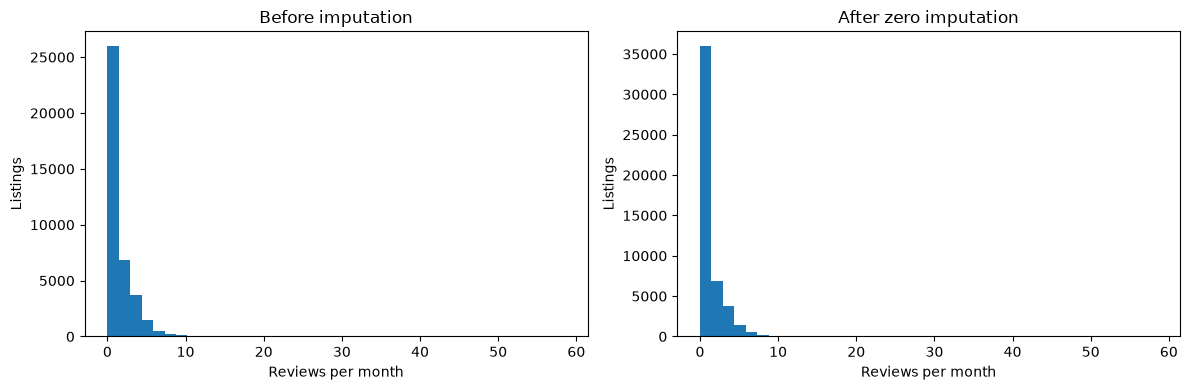

In [9]:
reviews_before = df["reviews_per_month"]
reviews_after = reviews_before.fillna(0)
comparison = pd.DataFrame({
    "Before": [reviews_before.mean(), reviews_before.median(), reviews_before.std(), reviews_before.skew()],
    "After": [reviews_after.mean(), reviews_after.median(), reviews_after.std(), reviews_after.skew()]
}, index=["Mean", "Median", "Standard Deviation", "Skewness"])
display(comparison.round(6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(reviews_before.dropna(), bins=40)
axes[0].set_title("Before imputation")
axes[1].hist(reviews_after, bins=40)
axes[1].set_title("After zero imputation")
for ax in axes: ax.set_xlabel("Reviews per month"); ax.set_ylabel("Listings")
plt.tight_layout()
plt.show()

**Important:** Filling here is only for distribution comparison. Do not use this prefilled data for model training. The fitted model's imputation is performed inside `pipeline.py`.

## 9. Missingness indicators: diagnostic example

In [10]:
missing_cols = ["name", "host_name", "last_review", "reviews_per_month"]
indicators = pd.DataFrame(index=df.index)
for col in missing_cols:
    indicators[col + "_missing"] = df[col].isna().astype(int)
display(indicators.head())
print("Indicator counts:")
print(indicators.sum())

,name_missing,host_name_missing,last_review_missing,reviews_per_month_missing
0,0,0,0,0
1,0,0,0,0
2,0,0,1,1
3,0,0,0,0
4,0,0,0,0


Indicator counts:
name_missing                    16
host_name_missing               21
last_review_missing          10052
reviews_per_month_missing    10052
dtype: int64


## 10. Check numerical log transformations (R4)

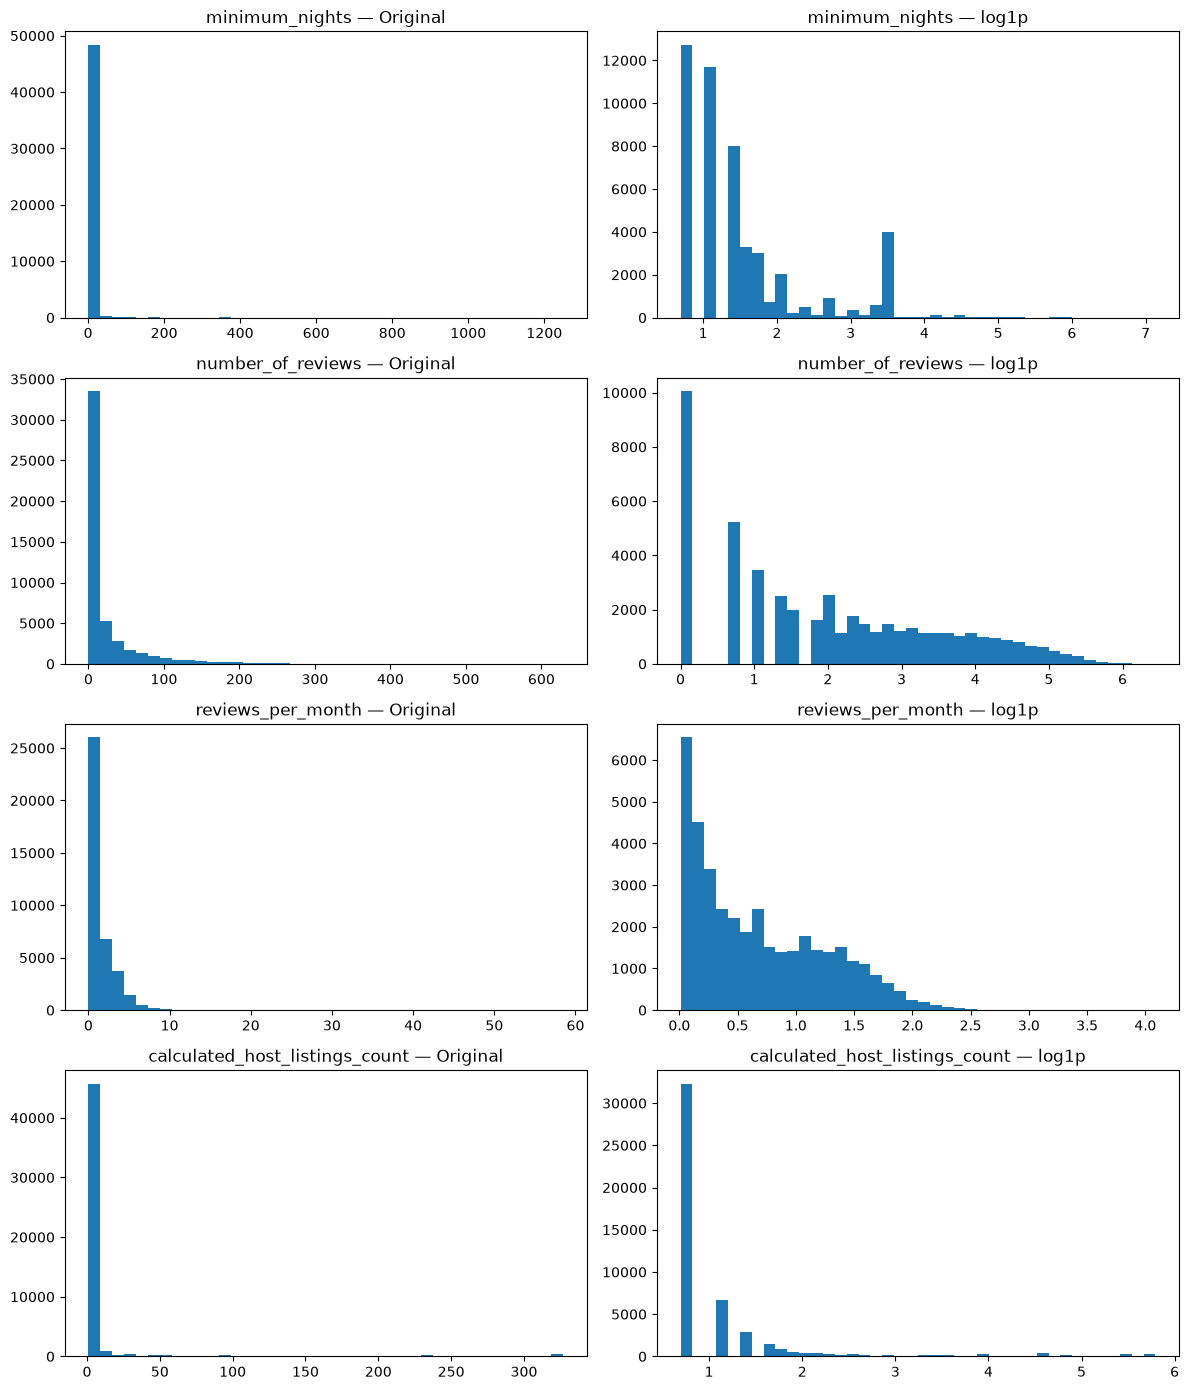

,Feature,Original Skew,Log Skew
0,minimum_nights,21.827,1.499
1,number_of_reviews,3.691,0.363
2,reviews_per_month,3.130,0.719
3,calculated_host_listings_count,7.933,3.280


In [11]:
skewed_columns = ["minimum_nights", "number_of_reviews", "reviews_per_month", "calculated_host_listings_count"]
fig, axes = plt.subplots(len(skewed_columns), 2, figsize=(12, 14))
skew_results = []
for i, col in enumerate(skewed_columns):
    original = df[col].dropna()
    transformed = np.log1p(original)
    axes[i, 0].hist(original, bins=40)
    axes[i, 0].set_title(f"{col} — Original")
    axes[i, 1].hist(transformed, bins=40)
    axes[i, 1].set_title(f"{col} — log1p")
    skew_results.append({"Feature": col, "Original Skew": original.skew(), "Log Skew": transformed.skew()})
plt.tight_layout()
plt.show()
skew_comparison = pd.DataFrame(skew_results)
display(skew_comparison.round(3))

## 11. Availability distribution

In [12]:
zero_share = (df["availability_365"] == 0).mean() * 100
print(f"Zero availability: {zero_share:.2f}%")
display(df["availability_365"].describe())

Zero availability: 35.86%


count    48895.000000
mean       112.781327
std        131.622289
min          0.000000
25%          0.000000
50%         45.000000
75%        227.000000
max        365.000000
Name: availability_365, dtype: float64

## 12. Categorical frequencies and rare neighbourhoods (R5)

In [13]:
categorical_columns = ["neighbourhood_group", "room_type", "neighbourhood"]
for col in categorical_columns:
    print("\nColumn:", col)
    print("Unique categories:", df[col].nunique())
    print(df[col].value_counts().head(10))

counts = df["neighbourhood"].value_counts()
print("\nTotal unique neighbourhoods:", len(counts))
for threshold in [10, 50, 100]:
    print(f"Neighbourhoods with fewer than {threshold} listings:", int((counts < threshold).sum()))


Column: neighbourhood_group
Unique categories: 5
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

Column: room_type
Unique categories: 3
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64

Column: neighbourhood
Unique categories: 221
neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64

Total unique neighbourhoods: 221
Neighbourhoods with fewer than 10 listings: 53
Neighbourhoods with fewer than 50 listings: 123
Neighbourhoods with fewer than 100 listings: 156


## 13. Encoding demonstrations (not used to fit the production model)

In [14]:
from sklearn.preprocessing import OneHotEncoder

sample = df[["room_type"]].head(5)
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = encoder.fit_transform(sample)
print("Room-type feature names:", encoder.get_feature_names_out())
print(encoded)

example = pd.DataFrame({"area": ["A", "A", "A", "A", "B", "B", "B", "C", "D"]})
rare_encoder = OneHotEncoder(min_frequency=3, handle_unknown="infrequent_if_exist", sparse_output=False)
result = rare_encoder.fit_transform(example)
print("\nRare-grouping feature names:", rare_encoder.get_feature_names_out())
print(result)

Room-type feature names: ['room_type_Entire home/apt' 'room_type_Private room']
[[0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]

Rare-grouping feature names: ['area_A' 'area_B' 'area_infrequent_sklearn']
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]


## 14. Final proposed treatments and save audit

In [15]:
treatments = {
    "id": "Drop: unique listing identifier",
    "host_id": "Drop: host identifier",
    "name": "Drop: high-cardinality free text; missingness investigated",
    "host_name": "Drop: high-cardinality names; missingness investigated",
    "last_review": "Drop raw date; missingness coincides with zero reviews",
    "reviews_per_month": "Zero imputation + missing indicator + log1p + StandardScaler",
    "price": "Target: exclude zero-price rows from supervised modeling",
    "neighbourhood_group": "One-hot; ignore unknown categories",
    "room_type": "One-hot; ignore unknown categories",
    "neighbourhood": "Rare grouping (min_frequency=50) + one-hot",
    "latitude": "Median fallback + StandardScaler",
    "longitude": "Median fallback + StandardScaler",
    "minimum_nights": "Median fallback + log1p + StandardScaler",
    "number_of_reviews": "Median fallback + log1p + StandardScaler",
    "calculated_host_listings_count": "Median fallback + log1p + RobustScaler",
    "availability_365": "Median fallback + MinMaxScaler"
}
audit["proposed treatment"] = audit["column"].map(treatments)
assert not audit["proposed treatment"].isna().any()
display(audit)
audit.to_csv("audit_table.csv", index=False)
print("Saved: audit_table.csv")

,column,dtype,% missing,distinct,min / max or top 3,outliers (IQR),proposed treatment
0,id,int64,0.00,48895,2539 to 36487245,0,Drop: unique listing identifier
1,name,str,0.03,47905,"['Hillside Hotel', 'Home away from home', 'New...",N/A,Drop: high-cardinality free text; missingness ...
2,host_id,int64,0.00,37457,2438 to 274321313,1526,Drop: host identifier
3,host_name,str,0.04,11452,"['Michael', 'David', 'Sonder (NYC)']",N/A,Drop: high-cardinality names; missingness inve...
4,neighbourhood_group,str,0.00,5,"['Manhattan', 'Brooklyn', 'Queens']",N/A,One-hot; ignore unknown categories
5,neighbourhood,str,0.00,221,"['Williamsburg', 'Bedford-Stuyvesant', 'Harlem']",N/A,Rare grouping (min_frequency=50) + one-hot
6,latitude,float64,0.00,19048,40.49979 to 40.91306,425,Median fallback + StandardScaler
7,longitude,float64,0.00,14718,-74.24442 to -73.71299,2833,Median fallback + StandardScaler
8,room_type,str,0.00,3,"['Entire home/apt', 'Private room', 'Shared ro...",N/A,One-hot; ignore unknown categories
9,price,int64,0.00,674,0 to 10000,2972,Target: exclude zero-price rows from supervise...


Saved: audit_table.csv


## 15. Notes for the justification report

- This audit contains all **16 raw columns**; `price` is the prediction target rather than an input feature.
- The raw dataset has 48,895 rows; restricting the supervised task to positive target prices leaves **48,884** rows.
- All numerical distribution and category analyses above use the **raw dataset for diagnostic purposes**. The final train/validation fold-specific imputation, scaling and grouping occur exclusively inside `pipeline.py`.
- MCAR/MAR/MNAR conclusions are **working hypotheses based on observed comparisons**, not definitive identification from observational data.
- For raw text/date fields, numerical means and standard deviations are not meaningful in their original representation; document frequency and missingness patterns and the reason for exclusion.
- IQR outliers are *flags*, not automatic removal rules.
